# Flower Classification: Work Notebook

This notebook solves the task in `01_flower_classification_project.ipynb`: classify photos of **roses, sunflowers and tulips** with only 100 training photos per flower, using **transfer learning** with MobileNetV2.

## Rules

- **Test set locked.** `data/test` is loaded only in step 6. Every decision is made on the validation accuracy.
- **Same preparation for every image.** The same `IMAGE_SIZE`, the same `preprocess_input` as a layer inside the model, the same frozen base.
- **Best model** = highest validation accuracy; if two models tie, the simpler one.
- **One table** with the results of all models so far after every model.
- **Save every model** to `models/` with `model.save`.

## Setup

Import the libraries and fix one image size and one random seed for the whole notebook.

In [2]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers
from keras.applications import mobilenet_v2
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

keras.utils.set_random_seed(42)
IMAGE_SIZE = (160, 160)  # one size for every model, so every photo is prepared the same way
DATA = Path("data")
CLASSES = ["rose", "sunflower", "tulip"]  # the folder names, in alphabetical order

# One plot style for the whole notebook
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3}
)

## 1. Get the Data

Display a few photos of every class from `data/train`.

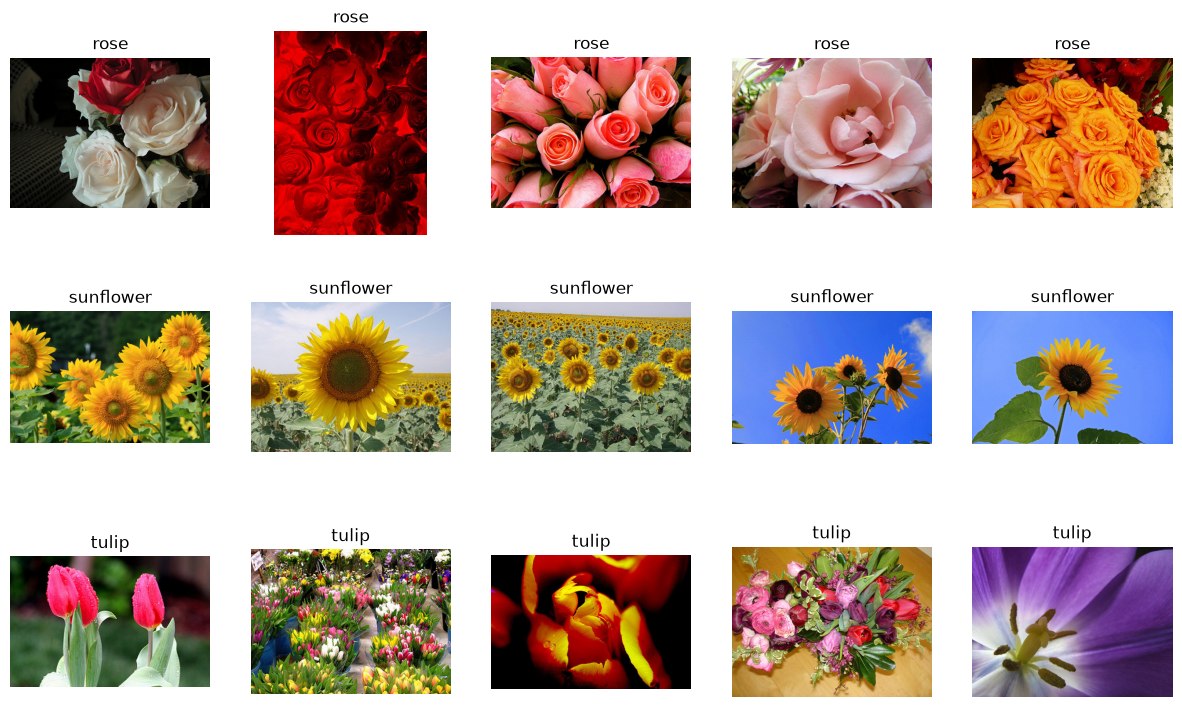

In [3]:
# Show 5 photos of every class from the training folder, to see what the model has to learn from
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for row, flower in enumerate(CLASSES):
    files = sorted((DATA / "train" / flower).glob("*.jpg"))[:5]
    for ax, file in zip(axes[row], files):
        ax.imshow(plt.imread(file))
        ax.set_title(flower)
        ax.axis("off")
plt.show()

## 2. Load the Training and Validation Images

Load `data/train` (shuffled with a fixed seed) and `data/validation` (`shuffle=False`) with one `image_size`. `data/test` stays locked.

In [4]:
def load_images(split, shuffle):
    """Return a dataset of (images, labels) batches from one folder: "train" or "validation"."""
    return keras.utils.image_dataset_from_directory(
        DATA / split, image_size=IMAGE_SIZE, batch_size=32, label_mode="int", shuffle=shuffle, seed=42
    )


# Only train and validation are loaded here: the test set stays locked until step 6
train_ds = load_images("train", shuffle=True)  # shuffled, so the batches mix the three flowers
valid_ds = load_images("validation", shuffle=False)  # fixed order, so predictions can be matched to photos
class_names = train_ds.class_names
print(class_names)
assert class_names == CLASSES

Found 300 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
['rose', 'sunflower', 'tulip']


## 3. Explore the Training Set

Display a grid of training photos with their labels. What makes the three flowers look different: colour, shape, the background?

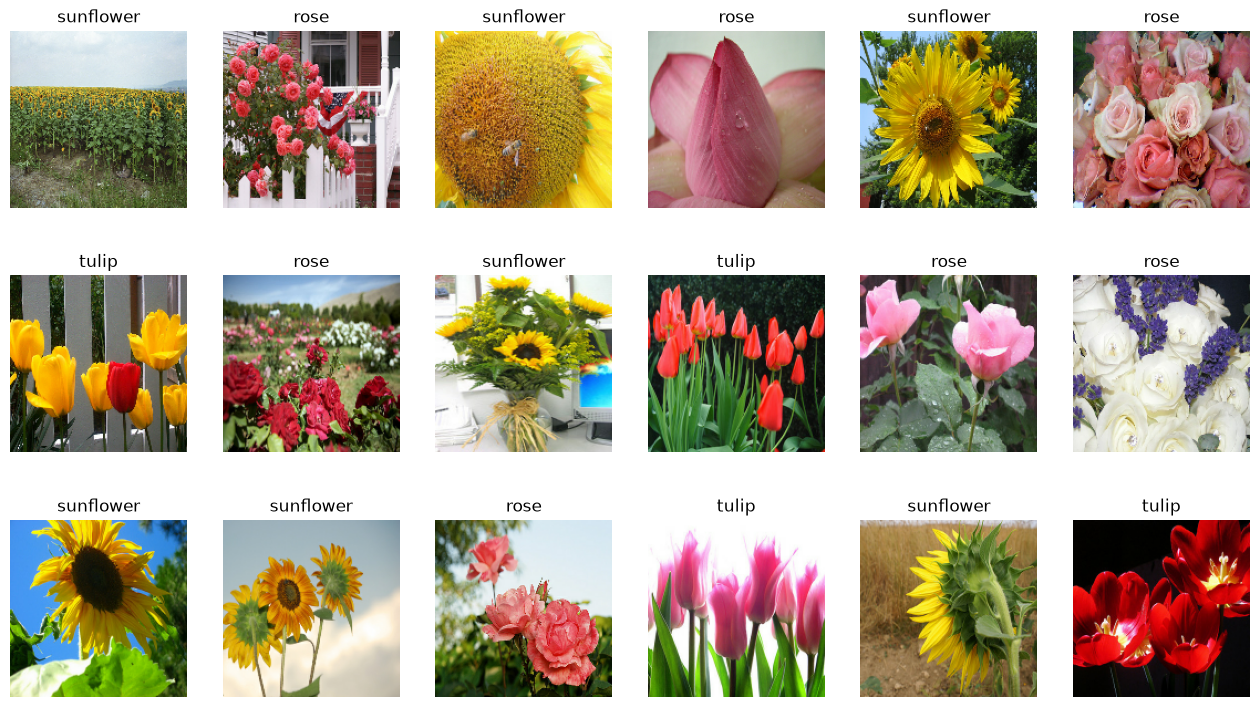

(32, 160, 160, 3) <dtype: 'float32'> 0.0 255.0


In [5]:
# Show the first batch of training photos with their labels
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(3, 6, figsize=(16, 9))
for ax, image, label in zip(axes.ravel(), images, labels):
    ax.imshow(image.numpy().astype("uint8"))
    ax.set_title(class_names[label])
    ax.axis("off")
plt.show()
print(images.shape, images.dtype, float(images.numpy().min()), float(images.numpy().max()))

## 4. A Baseline and a Pretrained Network

### Model 0: A Small CNN from Scratch (Baseline)

Train a small CNN on the 300 training photos only, with its preprocessing as a layer inside the model. It shows what 100 photos per flower can do **without** a pretrained network. This model is outside the brief: it is a baseline, not a candidate for the best model unless its validation accuracy says so.

### Model 1: Frozen MobileNetV2 with a Dense Head

Put `preprocess_input`, the frozen pretrained base and a new dense head into one model. Plot the learning curves: does it overfit?

In [6]:
def compile_and_fit(model, epochs, learning_rate=1e-3, initial_epoch=0):
    """Compile a classifier with Adam and train it on the flower images; return the learning curves."""
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        metrics=["accuracy"],
    )
    history = model.fit(
        train_ds, validation_data=valid_ds, epochs=epochs, initial_epoch=initial_epoch, verbose=0
    )
    return pd.DataFrame(history.history, index=history.epoch)


def plot_curves(logs, title):
    """Plot the training and validation loss and accuracy of one run."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title=f"{title}: loss")
    logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title=f"{title}: accuracy")
    plt.show()


def results_table():
    """One table with the validation accuracy of every model so far, best first."""
    table = pd.Series(results, name="validation accuracy").sort_values(ascending=False).to_frame()
    table["photos right (of 60)"] = (table["validation accuracy"] * 60).round().astype(int)
    return table.round(3)


results = {}  # the validation accuracy of every model, filled in after each model


c:\Users\mail4\Spiced\W5\project-flowers\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


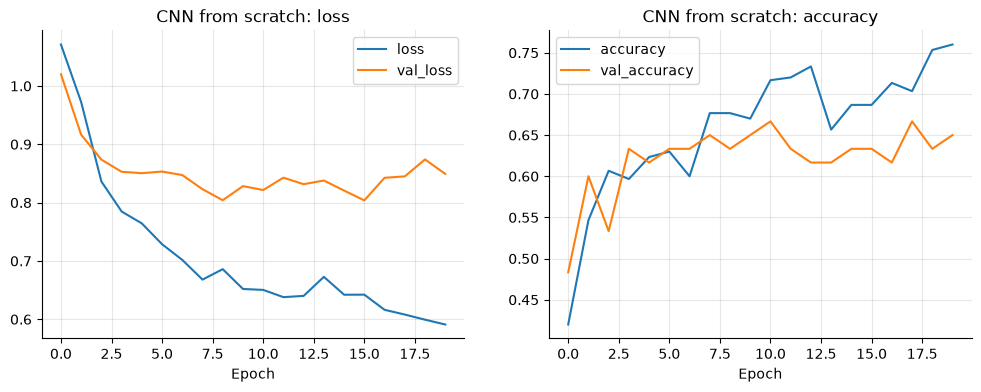

Parameters: 23,779
Final training accuracy: 0.760
Best validation accuracy: 0.667 at epoch 10


,validation accuracy,photos right (of 60)
CNN from scratch,0.65,39


In [7]:
keras.utils.clear_session()
keras.utils.set_random_seed(42)

# A small CNN from scratch: three conv blocks that double the filters, then a classifier
scratch_cnn = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        layers.Rescaling(scale=1 / 127.5, offset=-1),  # raw 0-255 photos in, -1 to 1 inside the model
        layers.Conv2D(16, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(3, activation="softmax"),
    ],
    name="scratch_cnn",
)

scratch_logs = compile_and_fit(scratch_cnn, epochs=20)
plot_curves(scratch_logs, "CNN from scratch")
results["CNN from scratch"] = scratch_cnn.evaluate(valid_ds, verbose=0)[1]
print(f"Parameters: {scratch_cnn.count_params():,}")
print(f"Final training accuracy: {scratch_logs['accuracy'].iloc[-1]:.3f}")
print(f"Best validation accuracy: {scratch_logs['val_accuracy'].max():.3f} at epoch {scratch_logs['val_accuracy'].idxmax()}")
results_table()


**Observation:** The CNN from scratch reaches a validation accuracy of 0.650, 39 of the 60 validation photos, with a training accuracy of 0.760 after 20 epochs. It learns something, since chance for three balanced classes is 0.333, but about one photo in three is wrong. The validation loss stops improving around epoch 8, at about 0.80, and rises slightly to about 0.85, while the training loss keeps falling to about 0.59: the overfitting pattern from the regularisation topic. The best validation accuracy of 0.667 (epoch 10, counting from 0) is only one photo better than the final 0.650, and the validation accuracy jumps between 0.60 and 0.67 from epoch to epoch because one photo is 1.7 percentage points. With only 300 photos, a network whose filters start random has to learn edges, textures and shapes from these photos alone. This is the baseline that the pretrained MobileNetV2 has to beat.


c:\Users\mail4\Spiced\W5\project-flowers\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


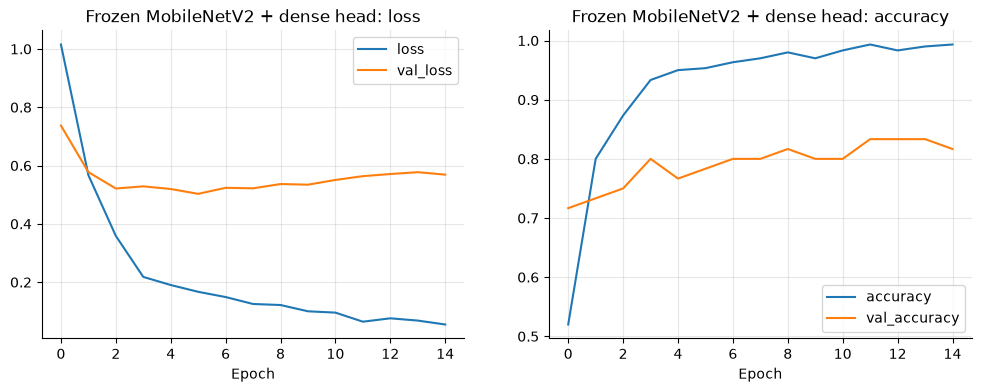

Trainable parameters: 3,843
Final training accuracy: 0.993
Best validation accuracy: 0.833 at epoch 11


,validation accuracy,photos right (of 60)
Frozen base + dense head,0.817,49
CNN from scratch,0.650,39


In [8]:
keras.utils.clear_session()
keras.utils.set_random_seed(42)

# The pretrained convolutional base without its 1,000-class classifier; pooling="avg" gives 1,280 numbers per photo
base = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)
base.trainable = False  # freeze: the new head must not damage the pretrained filters

frozen_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        layers.Rescaling(scale=1 / 127.5, offset=-1),  # the scaling of mobilenet_v2.preprocess_input
        base,
        layers.Dropout(0.2),
        layers.Dense(3, activation="softmax"),
    ],
    name="frozen_head",
)

frozen_logs = compile_and_fit(frozen_model, epochs=15)
plot_curves(frozen_logs, "Frozen MobileNetV2 + dense head")
results["Frozen base + dense head"] = frozen_model.evaluate(valid_ds, verbose=0)[1]
print(f"Trainable parameters: {sum(w.numpy().size for w in frozen_model.trainable_weights):,}")
print(f"Final training accuracy: {frozen_logs['accuracy'].iloc[-1]:.3f}")
print(f"Best validation accuracy: {frozen_logs['val_accuracy'].max():.3f} at epoch {frozen_logs['val_accuracy'].idxmax()}")
results_table()


In [9]:
# Save both models, so that step 6 can load them even after restarting the notebook
Path("models").mkdir(exist_ok=True)
scratch_cnn.save("models/scratch_cnn.keras")
frozen_model.save("models/frozen_head.keras")
print(sorted(path.name for path in Path("models").glob("*.keras")))


['frozen_head.keras', 'scratch_cnn.keras']


## 5. Improve the Model

### Model 2: Data Augmentation

Add random flips, rotations and zooms in front of the base and compare the validation accuracy with model 1.

### Model 3: Fine-Tuning

Unfreeze the top layers of the base and train them with a low learning rate. Keep the `BatchNormalization` layers in inference mode.

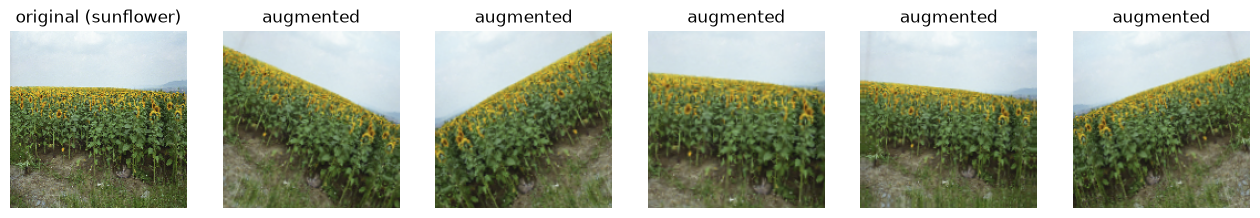

In [10]:
# Random changes that keep a flower a flower; Keras applies them only while training
augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),  # a mirrored rose is still a rose; upside down is not a natural photo
        layers.RandomRotation(0.1),  # up to 10 % of a full turn (36 degrees) in either direction
        layers.RandomZoom(0.2),  # zoom in or out by up to 20 %
    ],
    name="augmentation",
)

photo = images[:1]  # the first photo of the batch from step 3
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(photo[0].numpy().astype("uint8"))
axes[0].set_title(f"original ({class_names[labels[0]]})")
for ax in axes[1:]:
    ax.imshow(augmentation(photo, training=True)[0].numpy().astype("uint8"))  # training=True switches it on
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()


c:\Users\mail4\Spiced\W5\project-flowers\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


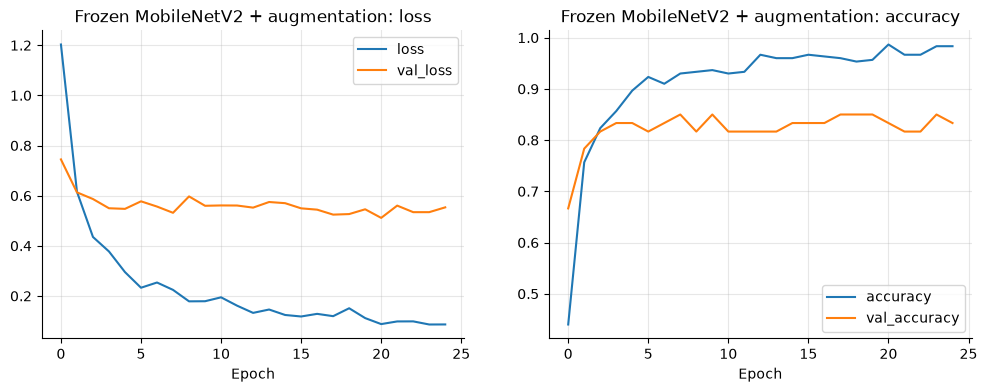

Final training accuracy: 0.983
Best validation accuracy: 0.850 at epoch 7


,validation accuracy,photos right (of 60)
Frozen base + augmentation,0.833,50
Frozen base + dense head,0.817,49
CNN from scratch,0.650,39


In [11]:
keras.utils.clear_session()
keras.utils.set_random_seed(42)

# Same frozen base and head as model 1; the augmentation comes first and is active only during training
augmented_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        augmentation,
        layers.Rescaling(scale=1 / 127.5, offset=-1),
        base,
        layers.Dropout(0.2),
        layers.Dense(3, activation="softmax"),
    ],
    name="augmented_head",
)

augmented_logs = compile_and_fit(augmented_model, epochs=25)  # more epochs: every epoch shows new variants, so it learns slower
plot_curves(augmented_logs, "Frozen MobileNetV2 + augmentation")
results["Frozen base + augmentation"] = augmented_model.evaluate(valid_ds, verbose=0)[1]
print(f"Final training accuracy: {augmented_logs['accuracy'].iloc[-1]:.3f}")
print(f"Best validation accuracy: {augmented_logs['val_accuracy'].max():.3f} at epoch {augmented_logs['val_accuracy'].idxmax()}")
results_table()


In [12]:
# Save the augmented model next to the other two models
augmented_model.save("models/augmented_head.keras")
print(sorted(path.name for path in Path("models").glob("*.keras")))


['augmented_head.keras', 'frozen_head.keras', 'scratch_cnn.keras']


In [13]:
keras.utils.clear_session()
keras.utils.set_random_seed(42)

# A fresh copy from the file, so the frozen models in memory keep their own base
fine_tuned = keras.models.load_model("models/augmented_head.keras")
fine_base = fine_tuned.get_layer(index=2)  # the MobileNetV2 base: augmentation, rescaling, base, dropout, dense
print(fine_base.name, len(fine_base.layers), "layers")

# Unfreeze only the top 30 layers; the lower layers keep their general edge and texture filters
fine_base.trainable = True
for layer in fine_base.layers[:-30]:
    layer.trainable = False
# BatchNormalization layers stay frozen, so they keep their ImageNet statistics while we train
for layer in fine_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_layers = [layer.name for layer in fine_base.layers if layer.trainable and layer.weights]
print(f"{len(trainable_layers)} layers with trainable weights, first: {trainable_layers[0]}")
print(f"Trainable parameters: {sum(w.numpy().size for w in fine_tuned.trainable_weights):,}")


mobilenetv2_1.00_160 155 layers
10 layers with trainable weights, first: block_14_expand
Trainable parameters: 1,514,563


c:\Users\mail4\Spiced\W5\project-flowers\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


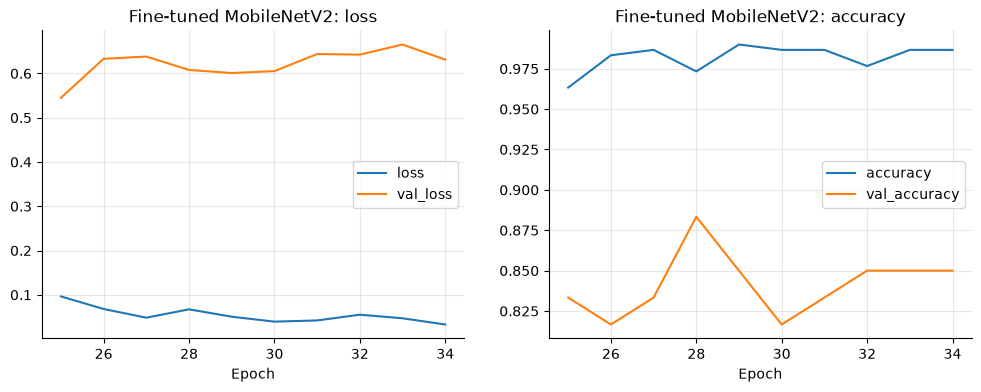

Final training accuracy: 0.987
Best validation accuracy: 0.883 at epoch 28


,validation accuracy,photos right (of 60)
Fine-tuned top layers,0.850,51
Frozen base + augmentation,0.833,50
Frozen base + dense head,0.817,49
CNN from scratch,0.650,39


In [14]:
# Continue training the augmented model's epochs, now with the top layers unfrozen and a very low learning rate
fine_logs = compile_and_fit(fine_tuned, epochs=35, learning_rate=1e-5, initial_epoch=25)
plot_curves(fine_logs, "Fine-tuned MobileNetV2")
results["Fine-tuned top layers"] = fine_tuned.evaluate(valid_ds, verbose=0)[1]
print(f"Final training accuracy: {fine_logs['accuracy'].iloc[-1]:.3f}")
print(f"Best validation accuracy: {fine_logs['val_accuracy'].max():.3f} at epoch {fine_logs['val_accuracy'].idxmax()}")
results_table()


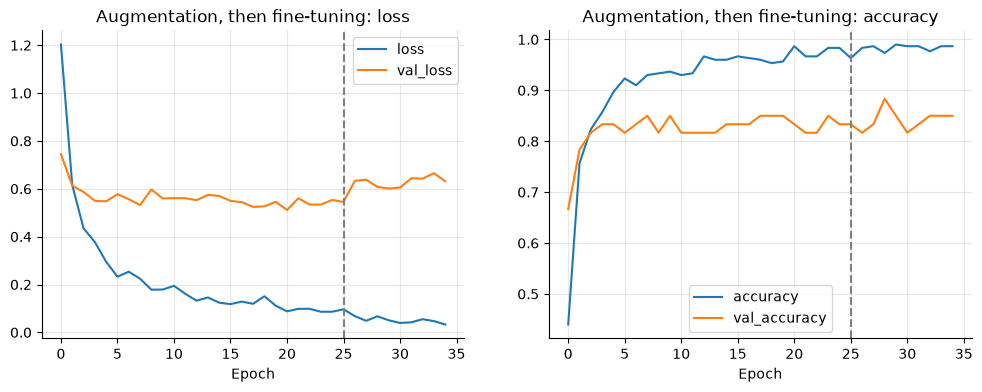

In [15]:
# The fine-tuning epochs continue the augmented model's 25 epochs, so join both logs into one run of 35 epochs
full_logs = pd.concat([augmented_logs, fine_logs])

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
full_logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title="Augmentation, then fine-tuning: loss")
full_logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title="Augmentation, then fine-tuning: accuracy")
for ax in (ax_loss, ax_acc):
    ax.axvline(25, color="grey", linestyle="--")  # fine-tuning starts here, with the top layers unfrozen
plt.show()


In [16]:
# Save the fine-tuned model next to the others; step 6 loads all four from this folder
fine_tuned.save("models/fine_tuned.keras")
print(sorted(path.name for path in Path("models").glob("*.keras")))


['augmented_head.keras', 'fine_tuned.keras', 'frozen_head.keras', 'scratch_cnn.keras']


## 6. Evaluate on the Test Set

Load the saved models and `data/test` (`shuffle=False`). Collect the validation and test accuracy of every model in one table, plot the confusion matrix of the best model and display every misclassified test photo.

In [17]:
# The test set is opened here for the first time, with the same image size and in a fixed order
test_ds = load_images("test", shuffle=False)
y_valid = np.concatenate([labels.numpy() for _, labels in valid_ds])
y_test = np.concatenate([labels.numpy() for _, labels in test_ds])

# Simplest model first: if two models tie on validation accuracy, the first one wins
model_files = {
    "CNN from scratch": "models/scratch_cnn.keras",
    "Frozen base + dense head": "models/frozen_head.keras",
    "Frozen base + augmentation": "models/augmented_head.keras",
    "Fine-tuned top layers": "models/fine_tuned.keras",
}
models = {name: keras.models.load_model(file) for name, file in model_files.items()}

rows = {}
test_predictions = {}
for name, model in models.items():
    valid_pred = model.predict(valid_ds, verbose=0).argmax(axis=1)
    test_predictions[name] = model.predict(test_ds, verbose=0).argmax(axis=1)
    rows[name] = {
        "validation accuracy": accuracy_score(y_valid, valid_pred),
        "test accuracy": accuracy_score(y_test, test_predictions[name]),
    }
final_table = pd.DataFrame(rows).T
final_table["photos right on test (of 30)"] = (final_table["test accuracy"] * 30).round().astype(int)
best_name = final_table["validation accuracy"].idxmax()  # chosen by validation accuracy only
print("Best model by validation accuracy:", best_name)
final_table.round(3)


Found 30 files belonging to 3 classes.
Best model by validation accuracy: Fine-tuned top layers


,validation accuracy,test accuracy,photos right on test (of 30)
CNN from scratch,0.650,0.767,23
Frozen base + dense head,0.817,0.867,26
Frozen base + augmentation,0.833,0.933,28
Fine-tuned top layers,0.850,0.933,28


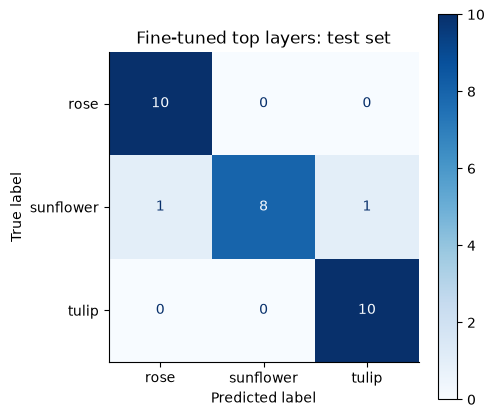

In [18]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions[best_name], display_labels=CLASSES, cmap="Blues", ax=ax
)
ax.set_title(f"{best_name}: test set")
ax.grid(False)
plt.show()


2 of 30 test photos are misclassified


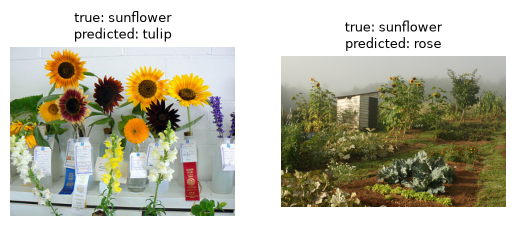

In [19]:
# Find the test photos the best model gets wrong; the dataset keeps the file order, so index i is file i
wrong = np.flatnonzero(test_predictions[best_name] != y_test)
print(f"{len(wrong)} of {len(y_test)} test photos are misclassified")

fig, axes = plt.subplots(1, max(len(wrong), 2), figsize=(3.2 * max(len(wrong), 2), 3.6))
for ax, i in zip(axes, wrong):
    ax.imshow(plt.imread(test_ds.file_paths[i]))
    ax.set_title(f"true: {CLASSES[y_test[i]]}\npredicted: {CLASSES[test_predictions[best_name][i]]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()


**Observation:** Both misclassified photos show sunflowers, and in both the sunflower is not the single close-up subject that most training photos show. The first photo shows a shelf with sunflowers in vases next to snapdragons and other flowers, with ribbons and labels, and the model predicts a tulip. The second photo is a wide garden scene, with the sunflowers small in the background behind vegetable plants and a shed, and the model predicts a rose. In both, other flowers or plants take up much of the picture, or the sunflower is tiny. The model seems to rely on the whole picture, not only on the sunflower. For the garden centre this means a customer should upload a photo with one flower in the middle, and a member of staff should check photos of bunches or whole gardens. Two photos are too few to be sure of this pattern.


## 7. Try the Model in the App

Check that the saved model takes raw photos (0 to 255), then run `uv run streamlit run app.py` and upload photos of your own.